## 01 - Creating Time Series

This notebook demonstrates several ways to create time series from transactional data. We will use a table containing Netflix releases. More information about the table can be found here: https://www.kaggle.com/datasets/anandshaw2001/netflix-movies-and-tv-shows

In [14]:
import pandas as pd         # Manipulação e análise de dados estruturados (DataFrames)
import seaborn as sns      # Visualização de dados estatísticos (gráficos estilizados)
import matplotlib.pyplot as plt  # Criação e personalização de gráficos


In [ ]:
df = pd.read_csv('netflix_titles.csv') # criando a tabela do tipo dataframe com pandas. 

In [15]:
# Exibe as 5 primeiras linhas do DataFrame para visualizar a estrutura e os dados
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,No Cast,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,No Director,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",No Country,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,No Director,No Cast,No Country,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,No Director,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [13]:
# Converte a coluna 'date_added' de texto para o formato de data (datetime)
# 'format': indica o padrão original do texto (ex: 'September 25, 2021')
# 'errors=coerce': transforma textos inválidos ou fora do padrão em valores nulos (NaT)
df['date_added'] = pd.to_datetime(df['date_added'], format='%B %d, %Y', errors = 'coerce')

# Exibe a quantidade total de valores nulos/faltantes em cada coluna do DataFrame
df.isna().sum()


show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [12]:
# Substitui os valores ausentes (nulos) por textos padronizados em colunas específicas
df['director'] = df['director'].fillna('No Director')
df['cast'] = df['cast'].fillna('No Cast')
df['country'] = df['country'].fillna('No Country')
df['rating'] = df['rating'].fillna('No Rating')
df['duration'] = df['duration'].fillna('No Duration')

# Remove do DataFrame as linhas onde a data de adição ('date_added') é nula/inválida
df = df[~df['date_added'].isna()]

# Exibe a contagem atualizada de valores nulos em todas as colunas para conferência
df.isna().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

# Análise dos Lançamentos da Netflix

* **Acumular dados:** Agrupamento mensal realizado utilizando contagem por mês (`resample('MS').size()`).
* **Tratamento de dados:** Verificação e preenchimento de eventuais dados faltantes na série temporal.
* **Visualização:** Geração do gráfico de séries temporais demonstrando a evolução das adições ao longo do tempo.

In [18]:
# Define a coluna 'date_added' como índice e agrupa os dados por mês ('MS' = Month Start),
# contando a quantidade total de lançamentos adicionados em cada mês
lancamentos = df.set_index('date_added').resample('MS').size()

In [19]:
# Remove do objeto 'lancamentos' o antepenúltimo elemento (a 3ª posição a contar do final)
# através do seu índice
lancamentos = lancamentos.drop(lancamentos.index[-3])

In [21]:
# Cria uma sequência contínua de datas mensais (início de cada mês - 'MS')
# do primeiro mês registrado (min) até o último (max)
all_months = pd.date_range(start=lancamentos.index.min(), end=lancamentos.index.max(), freq='MS')

# Identifica quais meses da sequência completa NÃO estão presentes no índice da série 'lancamentos'
missing_months = all_months.difference(lancamentos.index)

# Verifica a existência de lacunas e exibe o resultado
if missing_months.empty:
    print("Nenhum mês faltando.")  # Executado se a série temporal estiver 100% contínua
else:
    print("Meses faltando:", missing_months)  # Exibe a lista dos meses ausentes na sequência

Meses faltando: DatetimeIndex(['2021-07-01'], dtype='datetime64[ns]', freq='MS')


In [23]:
# Reorganiza o índice de 'lancamentos' usando a sequência completa de meses ('all_months').
# Meses que estavam faltando no conjunto de dados original são preenchidos com o valor 0.
lancamentos_zero = lancamentos.reindex(all_months, fill_value=0)

# Exibe a série temporal completa já tratada (sem lacunas de meses)
lancamentos_zero

2008-01-01      1
2008-02-01      1
2008-03-01      0
2008-04-01      0
2008-05-01      0
             ... 
2021-05-01    132
2021-06-01    207
2021-07-01      0
2021-08-01    178
2021-09-01    183
Freq: MS, Length: 165, dtype: int64

In [24]:
# Reorganiza a série temporal para incluir todos os meses da sequência ('all_months')
# e preenche os meses ausentes repetindo o último valor válido registrado (Forward Fill)
lancamentos_ffill = lancamentos.reindex(all_months).ffill()

# Exibe a série temporal tratada com o preenchimento por propagação de dados
lancamentos_ffill

2008-01-01      1.0
2008-02-01      1.0
2008-03-01      0.0
2008-04-01      0.0
2008-05-01      0.0
              ...  
2021-05-01    132.0
2021-06-01    207.0
2021-07-01    207.0
2021-08-01    178.0
2021-09-01    183.0
Freq: MS, Length: 165, dtype: float64

In [25]:
# Reorganiza a série temporal para incluir todos os meses da sequência ('all_months')
# e preenche os meses ausentes com o valor do próximo mês válido registrado (Backward Fill)
lancamentos_bfill = lancamentos.reindex(all_months).bfill()

# Exibe a série temporal tratada com o preenchimento de trás para a frente
lancamentos_bfill

2008-01-01      1.0
2008-02-01      1.0
2008-03-01      0.0
2008-04-01      0.0
2008-05-01      0.0
              ...  
2021-05-01    132.0
2021-06-01    207.0
2021-07-01    178.0
2021-08-01    178.0
2021-09-01    183.0
Freq: MS, Length: 165, dtype: float64

In [26]:
# Reorganiza a série temporal para incluir todos os meses da sequência ('all_months')
# e preenche os meses ausentes estimando valores intermediários por interpolação linear
lancamentos_neighbors = lancamentos.reindex(all_months).interpolate(method='linear')

# Exibe a série temporal tratada com os valores interpolados
lancamentos_neighbors

2008-01-01      1.0
2008-02-01      1.0
2008-03-01      0.0
2008-04-01      0.0
2008-05-01      0.0
              ...  
2021-05-01    132.0
2021-06-01    207.0
2021-07-01    192.5
2021-08-01    178.0
2021-09-01    183.0
Freq: MS, Length: 165, dtype: float64

<Axes: xlabel='date_added'>

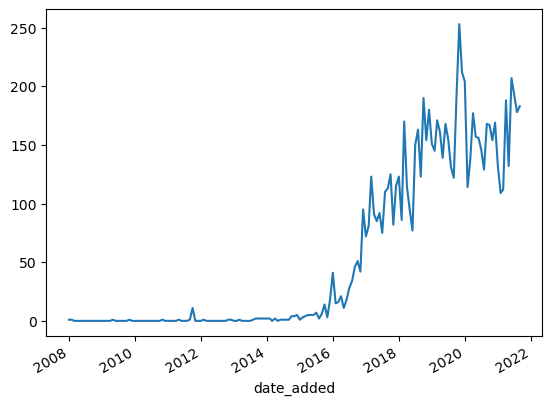

In [27]:
# Gera o gráfico de linha simples a partir da série temporal 'lancamentos'
# Exibe a variação do total de lançamentos ao longo do tempo (índice de datas)
lancamentos.plot()

<Axes: xlabel='date_added'>

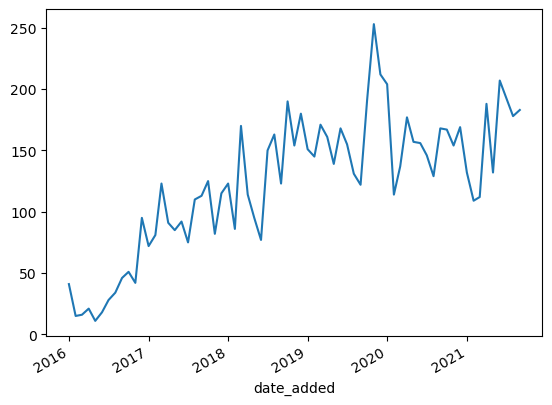

In [28]:
# Filtra os dados a partir do ano de 2016 (inclusive) usando o índice de datas
# e gera o gráfico de linha para visualizar os lançamentos desse período em diante
lancamentos[lancamentos.index.year >= 2016].plot()

In [29]:
def plot_series(serie):
    """
    Gera um gráfico de linha personalizado a partir de uma série temporal de lançamentos.
    
    Parâmetros:
    serie (pd.Series): Série temporal contendo as datas no índice e o total de lançamentos nos valores.
    """
    # Define o tamanho da figura (10 de largura por 6 de altura)
    plt.figure(figsize=(10, 6))
    
    # Plota a linha conectando as datas aos valores, marcando cada ponto com um círculo ('o')
    plt.plot(serie.index, serie, marker='o', linestyle='-')
    
    # Adiciona o título e os rótulos dos eixos com formatação de tamanho de fonte
    plt.title("Lançamentos por Mês e Ano", fontsize=14)
    plt.xlabel("Mês e Ano", fontsize=12)
    plt.ylabel("Quantidade de Lançamentos", fontsize=12)
    
    # Formata as marcações do eixo X para exibir 'Mês Abreviado Ano' (ex: 'Jan 2020') e rotaciona 45°
    plt.xticks(serie.index, serie.index.strftime('%b %Y'), rotation=45, ha='right')
    
    # Exibe a grade de fundo com linhas tracejadas e transparência leve (alpha=0.6)
    plt.grid(visible=True, linestyle='--', alpha=0.6)
    
    # Ajusta o espaçamento para evitar que os rótulos do eixo X fiquem cortados
    plt.tight_layout()
    
    # Exibe a figura gerada
    plt.show()

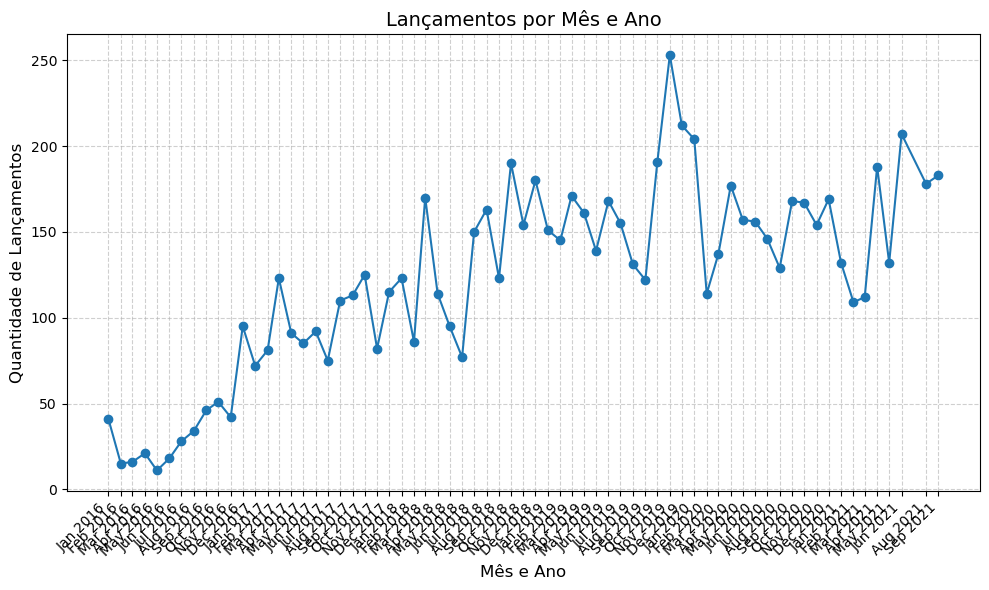

In [31]:
# Filtra a série temporal mantendo apenas os registros a partir do ano de 2016
lancamentos = lancamentos[lancamentos.index.year >= 2016]

# Chama a função personalizada para plotar o gráfico com o recorte de dados (2016 em diante)
plot_series(lancamentos)

In [32]:
# Cria uma sequência contínua de datas mensais (início de cada mês) do primeiro ao último registro
all_months = pd.date_range(start=lancamentos.index.min(), end=lancamentos.index.max(), freq='MS')

# 1. Preenchimento com Zero: atribui 0 a todos os meses que estavam ausentes
lancamentos_zero = lancamentos.reindex(all_months, fill_value=0)

# 2. Preenchimento com Valor Anterior (Forward Fill): repete o último valor válido registrado
lancamentos_ffill = lancamentos.reindex(all_months).ffill()

# 3. Preenchimento com Valor Posterior (Backward Fill): copia o próximo valor válido para trás
lancamentos_bfill = lancamentos.reindex(all_months).bfill()

# 4. Média dos vizinhos / Interpolação Linear: traça uma linha reta entre os pontos válidos vizinhos
lancamentos_neighbors = lancamentos.reindex(all_months).interpolate(method='linear')

# 5. Interpolação Linear: idêntico ao item 4 (calcula a transição direta em linha reta)
lancamentos_linear = lancamentos.reindex(all_months).interpolate(method='linear')

# 6. Interpolação Quadrática: estima os pontos nulos usando uma curva polinomial de 2º grau
lancamentos_quadratic = lancamentos.reindex(all_months).interpolate(method='quadratic')